# 📊 Ciclos Macro
Notebook 02: Modeling

## Preliminares

In [1]:
import pandas as pd
import numpy as np

# Algoritmos de Modelado No Supervisado y Reducción de Dimensionalidad
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

# Escalado
from sklearn.preprocessing import StandardScaler

# Métricas de Evaluación y Selección de Hiperparámetros (k clusters / n_components)
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

from src.config import clean_data_file
from src.modeling_functions import *

In [2]:
# Abrir fichero de datos
df = pd.read_parquet(clean_data_file)
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 236 entries, 2007-02-28 to 2026-09-30
Data columns (total 20 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   real_yield_10y                           236 non-null    float64
 1   spy                                      236 non-null    float64
 2   oil_ret_1m                               236 non-null    float64
 3   gold_ret_1m                              236 non-null    float64
 4   spy_ret_1m                               236 non-null    float64
 5   dxy_broad_goods_ret_1m                   236 non-null    float64
 6   vix_index_ret_1m                         236 non-null    float64
 7   oil_ret_12m                              236 non-null    float64
 8   gold_ret_12m                             236 non-null    float64
 9   spy_ret_12m                              236 non-null    float64
 10  cpi_headline_lag1_ret_12m      

In [3]:
# Se separan las variables de precio
price_cols = ['spy']
df_prices = df[price_cols].copy()

df = df.drop(price_cols, axis=1)
df_prices.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 236 entries, 2007-02-28 to 2026-09-30
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   spy     236 non-null    float64
dtypes: float64(1)
memory usage: 3.7 KB


In [4]:
# Escalar variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# PCA: Reducción de dimensionalidad a 3 factores principales
pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"Varianza explicada por componente: {pca.explained_variance_ratio_}")

Varianza explicada por componente: [0.20073074 0.18670073 0.11088032]


* Entre los 3 componentes se alcanza un 50% de varianza explicada.

In [5]:
# Cargas por componente
loadings_3d = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2', 'PC3'],
    index=df.columns,
)
print("Cargas factoriales por componente:")
print(loadings_3d.round(3))

Cargas factoriales por componente:
                                           PC1    PC2    PC3
real_yield_10y                          -0.074 -0.052 -0.519
oil_ret_1m                              -0.017  0.282  0.103
gold_ret_1m                             -0.084  0.193 -0.192
spy_ret_1m                               0.106  0.450  0.018
dxy_broad_goods_ret_1m                  -0.013 -0.409  0.067
vix_index_ret_1m                        -0.069 -0.374  0.028
oil_ret_12m                              0.208  0.003  0.269
gold_ret_12m                            -0.147  0.094 -0.109
spy_ret_12m                              0.340  0.120  0.193
cpi_headline_lag1_ret_12m                0.198 -0.175 -0.042
industrial_production_lag1_ret_12m       0.410 -0.093  0.026
m2_money_supply_lag1_ret_12m            -0.156  0.075  0.609
real_yield_10y_change_1m                 0.074 -0.244  0.058
unemployment_rate_lag1_change_12m       -0.385  0.152  0.012
fed_funds_rate_lag1_change_12m           0.341 -0.

Se observa que cada uno de los 3 ejes se ha especializado de forma casi ortogonal en una dimensión concreta del sistema financiero y macroeconómico:

**PC1: Eje de Sentimiento de Mercado (Risk-On / Risk-Off a corto plazo)**

Separa los períodos de euforia y expansión bursátil de los shocks inmediatos de liquidez y aversión al riesgo.
* Cargas positivas dominantes: `spy_ret_1m` / `oil_ret_1m` / `gold_ret_1m`
* Cargas negativas dominantes: `st_louis_financial_stress_change_1m` / `dxy_broad_goods_ret_1m` / `vix_index_ret_1m`

**PC2: Ciclo Económico Real (Deterioro del Empleo vs. Expansión Industrial y Tipos)**

Mira la salud del mercado laboral frente a la producción y la respuesta de la Fed.
* Cargas positivas dominantes: `unemployment_rate_lag1_change_12m` / `m2_money_supply_lag1_ret_12m` / `st_louis_financial_stress_yeo`
* Cargas negativas dominantes: `industrial_production_lag1_ret_12m` / `fed_funds_rate_lag1_change_12m` / `cpi_headline_lag1_ret_12m`

**PC3: Régimen de Liquidez Monetaria y Retorno de Activos Reales**

Captura la oferta de dinero en el sistema frente al costo real del capital, y cómo eso impulsa las tendencias a 12 meses de los activos.
* Cargas positivas dominantes: `m2_money_supply_lag1_ret_12m` / `oil_ret_12m` / `spy_ret_12m`
* Cargas negativas dominantes: `real_yield_10y` / `fed_funds_rate_lag1_change_12m` / `unemployment_rate_lag1_change_3m_yeo`


In [6]:
# K-Means sobre el espacio PCA
kmeans = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_pca)

# Evaluación de la calidad del agrupamiento
print(f"Silhouette Score (K-Means): {silhouette_score(X_pca, kmeans_labels):.4f}")

Silhouette Score (K-Means): 0.3510


In [ ]:
# Se entrena el modelo GMM con covarianza = "diag"
gmm = GaussianMixture(
    n_components=4,
    covariance_type="diag",  
    n_init=20,
    random_state=42,
)
gmm.fit(X_pca)
gmm_labels = gmm.predict(X_pca)
gmm_probs = gmm.predict_proba(X_pca)  # Probabilidad de pertenecer a cada régimen

print(f"Silhouette Score (GMM):     {silhouette_score(X_pca, gmm_labels):.4f}")
print(f"GMM BIC Score:              {gmm.bic(X_pca):.2f}")  # Menor BIC = mejor ajuste

Silhouette Score (GMM):     0.2657
GMM BIC Score:              2629.12


In [9]:
# Medias por cluster
df_analysis = df.copy()
df_analysis['regime'] = gmm_labels

profile = df_analysis.groupby('regime').mean().T
print("\nPerfil macro por Régimen:")
print(profile.round(3))


Perfil macro por Régimen:
regime                                       0      1      2      3
real_yield_10y                           0.927 -0.912  1.264  0.808
oil_ret_1m                               0.015  0.051  0.008 -0.018
gold_ret_1m                              0.008 -0.004  0.032  0.007
spy_ret_1m                               0.022  0.019  0.000 -0.024
dxy_broad_goods_ret_1m                  -0.003 -0.001  0.001  0.010
vix_index_ret_1m                        -0.047  0.049  0.019  0.194
oil_ret_12m                              0.070  0.585 -0.352  0.078
gold_ret_12m                             0.108  0.079  0.154  0.148
spy_ret_12m                              0.145  0.275 -0.185  0.050
cpi_headline_lag1_ret_12m                0.026  0.035  0.006  0.027
industrial_production_lag1_ret_12m       0.016  0.014 -0.108  0.006
m2_money_supply_lag1_ret_12m             0.044  0.189  0.101  0.058
real_yield_10y_change_1m                 0.001  0.019 -0.064  0.022
unemployment_rate_lag

## Análisis de cada cluster
**Régimen 0: Expansión Sostenida / "Goldilocks"**

Es el régimen de estabilidad por excelencia, con inflación controlada y variación de tasas casi nula. La volatilidad es baja y los activos de riesgo con avances consistentes.

**Régimen 1: Reflación Agresiva / Boom de Liquidez**

Inyección masiva de liquidez, tasas reales negativas, recortes de tipos y desempleo recuperándose rápido.

**Régimen 2: Recesión Profunda / Bear Market Severo**

Colapso de la economia real, con el desempleo aumentando año a año mientras la produccion industrial se desploma. La Reserva Federal responde con recorte de tasas e inyección de masa monetaria. El VIX promedio es elevado.

**Régimen 3: Fin de Ciclo / Sobrecalentamiento y Volatilidad**

Es una economía donde el crecimiento se estanca, con estrés financiero y volatilidad elevados.



In [10]:
print("Distribución de meses por régimen:")
print(df_analysis['regime'].value_counts().sort_index())

Distribución de meses por régimen:
regime
0    136
1     18
2     20
3     62
Name: count, dtype: int64


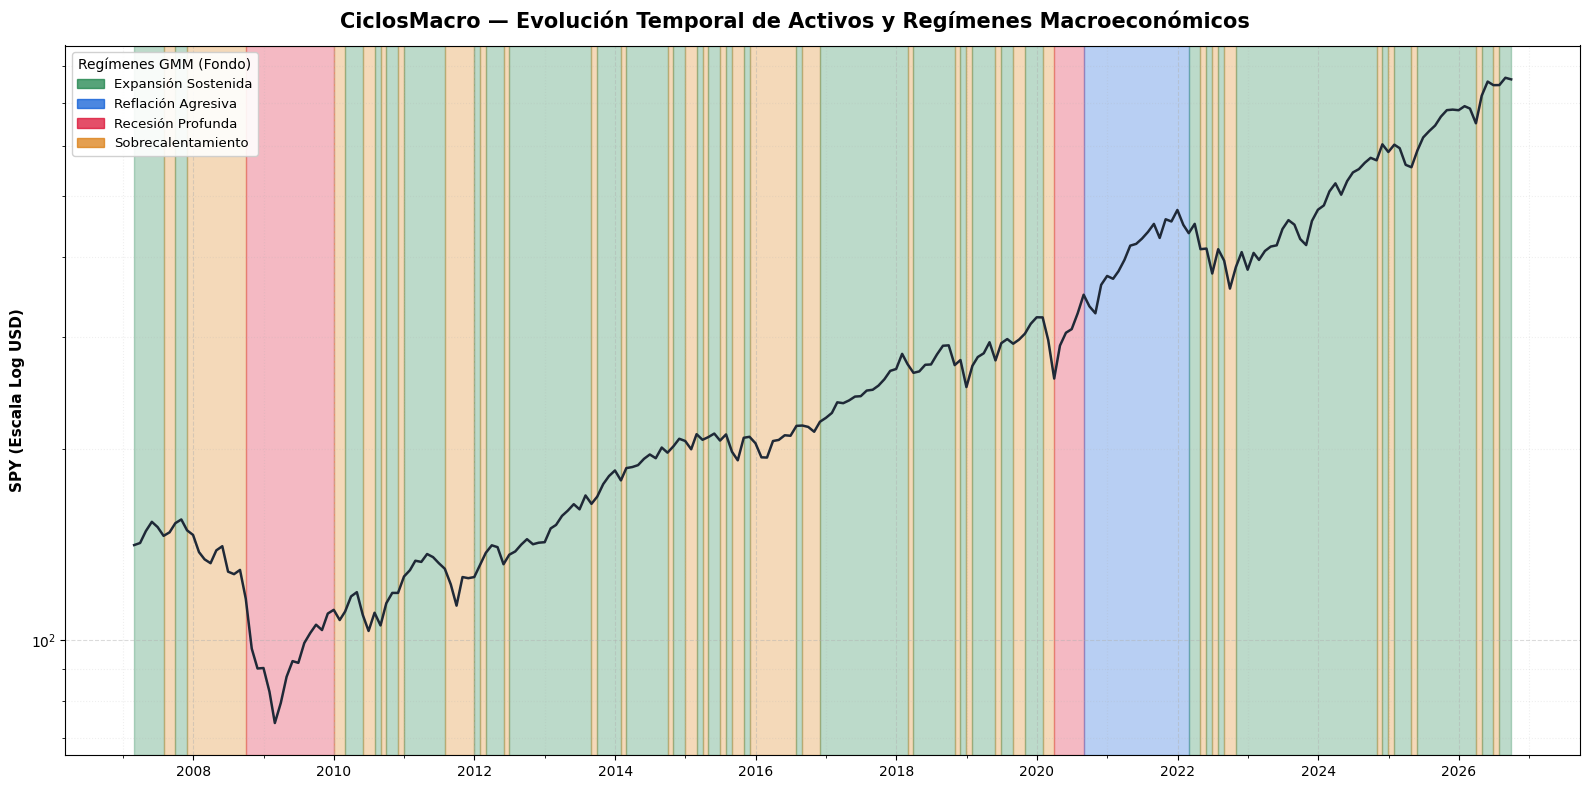

In [ ]:
# Graficar la evolución temporal de los ciclos
# Extraer las etiquetas del modelo GMM 3D ajustado
gmm_regimes = pd.Series(gmm.predict(X_pca), index=df.index)

fig, axes = plot_regimes_timeline(
    df_prices=df_prices,  
    regime_series=gmm_regimes,
    assets=["spy"],
    figsize=(16, 8),
    log_scale=True,
)